# Imports


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import sys
sys.path.append("..") 
from src.config import DATA_DIR
from src.data import load_csv

# Data Load
The data was already split when downloading it from the source. It does not mention, however, how the data was split meaning we do not know if its stratified or not, or what the test size is. 
* We calculated the test size to be approximately 0.08
* Using the descriptive summaries for the dataset we discovered it was split temporally with the tweets in the test set preceding the tweets in the training set 
    * Test covers the date range 03/02/2020 - 03/16/2020
    * Train covers the range 03/16/2020 - 04/14/2020

We decided to perform most of the EDA on the training data to prevent the testing data from influencing decisions. We did do some verifications like consistent column names and checking if there were missing values.

Most of the column names are self explanatory.
* The "UserName" and "ScreenName" columns are ID's that I'd guess they were anonymized  
* The "location" column appears to be inconsistent with how it lists the locations
* The "tweet at" column contains dates so it can be converted to date time obejcts
* Just from the head alone we know there is missing data

In [2]:
train_df = load_csv(DATA_DIR / "Corona_NLP_train.csv")
test_df = load_csv(DATA_DIR / "Corona_NLP_test.csv")

In [3]:
train_df.head()

,UserName,ScreenName,Location,TweetAt,OriginalTweet,Sentiment
0,3799,48751,London,16-03-2020,@MeNyrbie @Phil_Gahan @Chrisitv https://t.co/i...,Neutral
1,3800,48752,UK,16-03-2020,advice Talk to your neighbours family to excha...,Positive
2,3801,48753,Vagabonds,16-03-2020,Coronavirus Australia: Woolworths to give elde...,Positive
3,3802,48754,NaN,16-03-2020,My food stock is not the only one which is emp...,Positive
4,3803,48755,NaN,16-03-2020,"Me, ready to go at supermarket during the #COV...",Extremely Negative


In [4]:
test_df.head()

,UserName,ScreenName,Location,TweetAt,OriginalTweet,Sentiment
0,1,44953,NYC,02-03-2020,TRENDING: New Yorkers encounter empty supermar...,Extremely Negative
1,2,44954,"Seattle, WA",02-03-2020,When I couldn't find hand sanitizer at Fred Me...,Positive
2,3,44955,NaN,02-03-2020,Find out how you can protect yourself and love...,Extremely Positive
3,4,44956,Chicagoland,02-03-2020,#Panic buying hits #NewYork City as anxious sh...,Negative
4,5,44957,"Melbourne, Victoria",03-03-2020,#toiletpaper #dunnypaper #coronavirus #coronav...,Neutral


In [5]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41157 entries, 0 to 41156
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   UserName       41157 non-null  int64
 1   ScreenName     41157 non-null  int64
 2   Location       32567 non-null  str  
 3   TweetAt        41157 non-null  str  
 4   OriginalTweet  41157 non-null  str  
 5   Sentiment      41157 non-null  str  
dtypes: int64(2), str(4)
memory usage: 1.9 MB


In [6]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3798 entries, 0 to 3797
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   UserName       3798 non-null   int64
 1   ScreenName     3798 non-null   int64
 2   Location       2964 non-null   str  
 3   TweetAt        3798 non-null   str  
 4   OriginalTweet  3798 non-null   str  
 5   Sentiment      3798 non-null   str  
dtypes: int64(2), str(4)
memory usage: 178.2 KB


## Finding the Test split


In [7]:
test_split = len(test_df) / (len(train_df) + len(test_df))
print(test_split)

0.08448448448448448


## Descriptive Statistics

In [8]:
id_cols = ["UserName", "ScreenName"]

for col in id_cols:
    print(f"{col}: unique={train_df[col].is_unique}, "
          f"consecutive={(train_df[col].diff().dropna() == 1).all()}")

offset = (train_df["ScreenName"] - train_df["UserName"]).unique()
print("ScreenName - UserName offsets:", offset)

UserName: unique=True, consecutive=True
ScreenName: unique=True, consecutive=True
ScreenName - UserName offsets: [44952]


In [9]:
train_df.describe()

,UserName,ScreenName
count,41157.000000,41157.000000
mean,24377.000000,69329.000000
std,11881.146851,11881.146851
min,3799.000000,48751.000000
25%,14088.000000,59040.000000
50%,24377.000000,69329.000000
75%,34666.000000,79618.000000
max,44955.000000,89907.000000


In [10]:
test_df.describe()

,UserName,ScreenName
count,3798.000000,3798.000000
mean,1899.500000,46851.500000
std,1096.532489,1096.532489
min,1.000000,44953.000000
25%,950.250000,45902.250000
50%,1899.500000,46851.500000
75%,2848.750000,47800.750000
max,3798.000000,48750.000000


## Determing the Stratification Used
The descriptive summaries indicated the test set contains tweets from earlier dates than the train set. The same can be said for users.

When comparing the two data sets we found the tweets from the test set precede the tweets from the training set

In [11]:
for df in (train_df, test_df):
    df["TweetAt"] = pd.to_datetime(df["TweetAt"], format="%d-%m-%Y")

train_df["TweetAt"].dtype, test_df["TweetAt"].dtype

(dtype('<M8[us]'), dtype('<M8[us]'))

In [12]:
ranges = pd.DataFrame({
    "train": [train_df["TweetAt"].min(), train_df["TweetAt"].max()],
    "test":  [test_df["TweetAt"].min(),  test_df["TweetAt"].max()],
}, index=["first", "last"])
ranges

,train,test
first,2020-03-16,2020-03-02
last,2020-04-14,2020-03-16


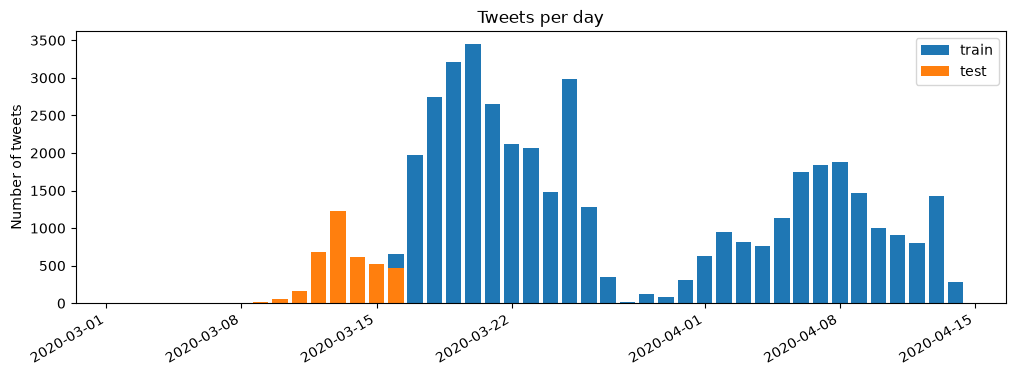

In [13]:
train_daily = train_df.groupby("TweetAt").size()
test_daily = test_df.groupby("TweetAt").size()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(train_daily.index, train_daily.values, label="train")
ax.bar(test_daily.index, test_daily.values, label="test")
ax.set_title("Tweets per day")
ax.set_ylabel("Number of tweets")
ax.legend()
fig.autofmt_xdate()
plt.show()

# Distributions and Outliers 
For numeric colummns the distribution was flat while the boxplot revealed no outliers

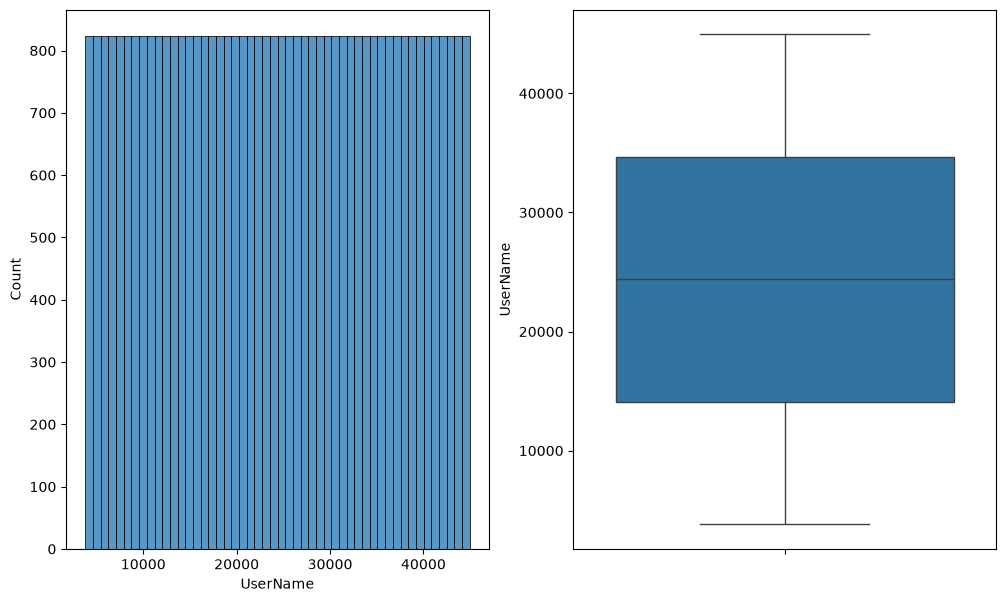

In [14]:
fig, axes = plt.subplots(1,2, figsize =(12,7))
sns.histplot(train_df["UserName"], bins=50, ax =axes[0])
sns.boxplot(train_df["UserName"], ax=axes[1])
plt.show()

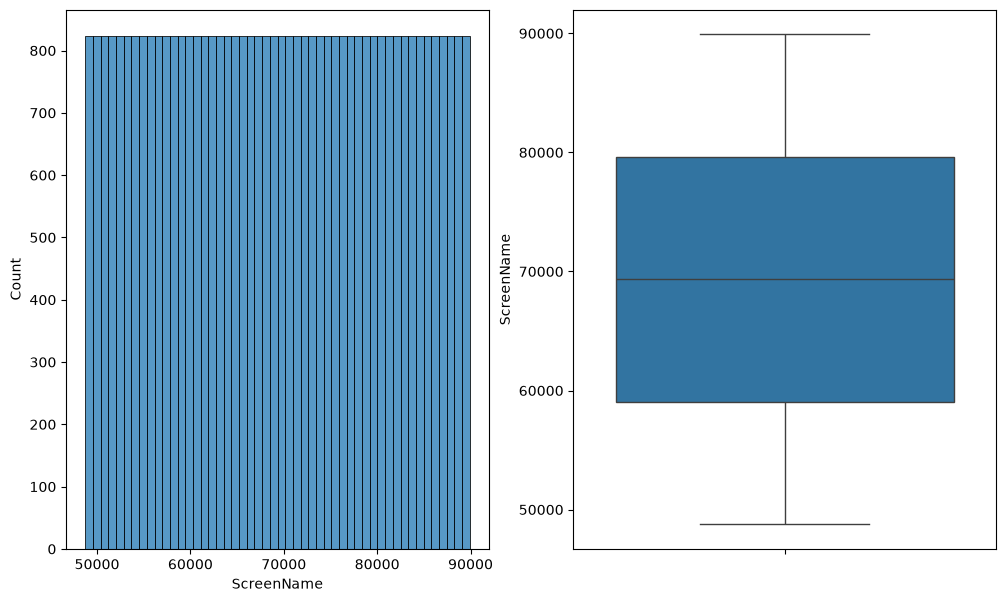

In [15]:
fig, axes = plt.subplots(1,2, figsize =(12,7))
sns.histplot(train_df["ScreenName"], bins=50, ax =axes[0])
sns.boxplot(train_df["ScreenName"], ax=axes[1])
plt.show()

# Labels and Class Balance

The dataset contained 5 unbalanced classes. Positve had the largest proportion at 27.752266% and extremely negative was the smallest accounting for 13.317297%. Something I thought was interesting was the extreme values having the lowest percentages in the data set. Comparing the column percentages for the train and test splits reveal the split was not stratified.

In [16]:
train_df["Sentiment"].value_counts(normalize = True) * 100

Sentiment
Positive              27.752266
Negative              24.095537
Neutral               18.740433
Extremely Positive    16.094468
Extremely Negative    13.317297
Name: proportion, dtype: float64

In [17]:
test_df["Sentiment"].value_counts(normalize = True) * 100

Sentiment
Negative              27.409163
Positive              24.934176
Neutral               16.298052
Extremely Positive    15.771459
Extremely Negative    15.587151
Name: proportion, dtype: float64

<Axes: title={'center': 'Test y Distribution'}, xlabel='Sentiment', ylabel='Percent'>

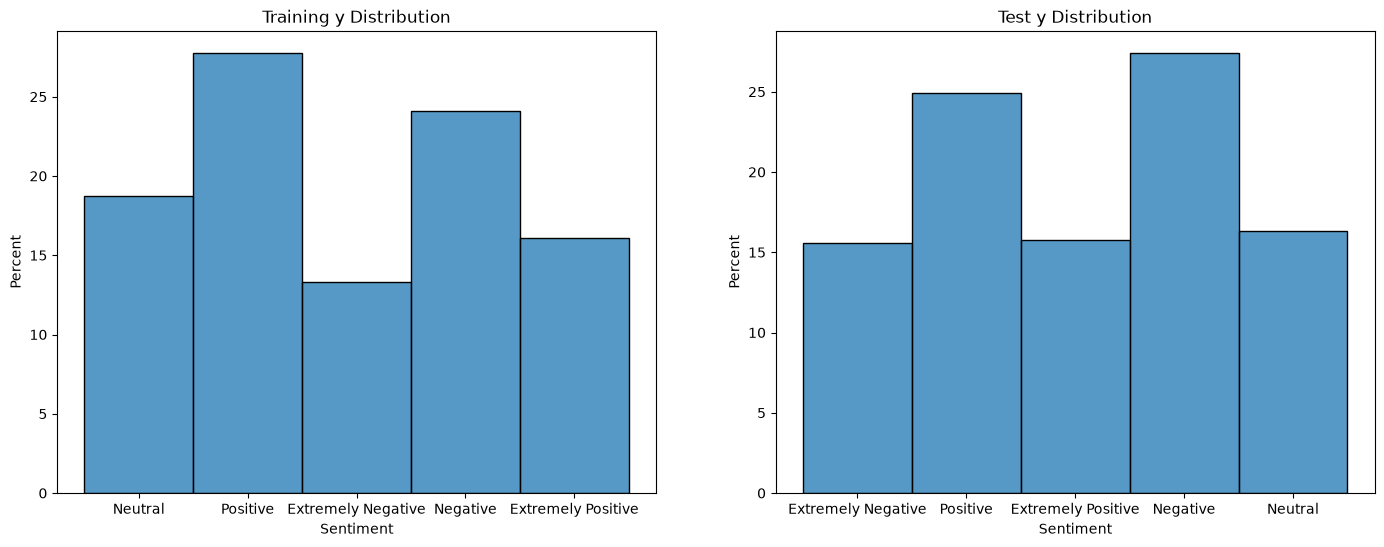

In [18]:
fig, axes = plt.subplots(1,2,figsize=(17,6))
axes[0].set_title("Training y Distribution")
axes[1].set_title("Test y Distribution")
sns.histplot(train_df["Sentiment"], ax=axes[0] ,stat = "percent")
sns.histplot(test_df["Sentiment"], ax=axes[1] ,stat = "percent")

# Missing Values

In [19]:
loc = train_df["Location"]
print(f"Missing: {loc.isna().mean():.1%}, unique values: {loc.nunique()}")
loc.value_counts().head(20)

Missing: 20.9%, unique values: 12220


Location
London                     540
United States              528
London, England            520
New York, NY               395
Washington, DC             373
United Kingdom             337
Los Angeles, CA            281
India                      268
UK                         232
Australia                  225
USA                        223
Canada                     191
England, United Kingdom    191
Toronto, Ontario           160
Global                     159
Chicago, IL                155
California, USA            153
San Francisco, CA          152
Boston, MA                 150
New York, USA              140
Name: count, dtype: int64

# Checking for Duplicates and Leakage

In [20]:
#Checking if there are duplicate tweets among the datasets
for name, df in [("train", train_df), ("test", test_df)]:
    full_row = df.duplicated().sum()
    text_only = df["OriginalTweet"].duplicated().sum()
    print(f"{name}: {full_row} duplicate rows, {text_only} duplicate tweet texts")

train: 0 duplicate rows, 0 duplicate tweet texts
test: 0 duplicate rows, 0 duplicate tweet texts


In [21]:
#Checking if the Datasets share any tweets between eachother
train_texts = set(train_df["OriginalTweet"])
test_texts = set(test_df["OriginalTweet"])
shared = train_texts & test_texts

print(f"Unique texts shared by train and test: {len(shared)}")
print(f"Test rows affected: {test_df['OriginalTweet'].isin(shared).sum()} / {len(test_df)}")

Unique texts shared by train and test: 0
Test rows affected: 0 / 3798


## Near Duplicates After Normalization
Exact matching found no duplicates, but it only catches tweets that are identical character for character. Retweets and copy-pasted tweets usually differ in ways that don't change their meaning such as different shortened link or a different @reply target. We Normalized the text to catch these duplicates.

`normalize_for_dedup` applies, in order:
1. `html.unescape`: HTML entities become characters (`&amp;` → `&`).
2. Lowercase: `BOC: SURVEY` and `BoC: Survey` match.
3. Remove URLs: every tweet gets a unique t.co link, which hides otherwise identical text.
4. Remove @mentions: replies to different users with the same body match. Hashtags are
   kept because they carry meaning (e.g. `#panicbuying`).
5. Collapse whitespace and strip: line breaks and double spaces don't create differences.

The result goes into a new `text_norm` column; `OriginalTweet` is never modified.
The trade-off: too light a normalization misses retweets; too aggressive and unrelated
tweets collide.

In [22]:
# TODO: move to src/preprocessing.py
 
import html

def normalize_for_dedup(s: pd.Series) -> pd.Series:
    return (
        s.map(html.unescape)                                  # &amp; -> &
         .str.lower()
         .str.replace(r"https?://\S+", " ", regex=True)       # URLs
         .str.replace(r"@\w+", " ", regex=True)               # @mentions
         .str.replace(r"\s+", " ", regex=True)                # collapse whitespace / \r\n
         .str.strip()
    )

train_df["text_norm"] = normalize_for_dedup(train_df["OriginalTweet"])
test_df["text_norm"] = normalize_for_dedup(test_df["OriginalTweet"])

shared_norm = set(train_df["text_norm"]) & set(test_df["text_norm"])
print(f"Duplicate normalized texts in train: {train_df['text_norm'].duplicated().sum()}")
print(f"Normalized texts shared by train/test: {len(shared_norm)}")
print(f"Test rows affected: {test_df['text_norm'].isin(shared_norm).sum()}")

Duplicate normalized texts in train: 75
Normalized texts shared by train/test: 6
Test rows affected: 7


### Mention-only tweets
14 train tweets (0 in test) consist only of @mentions so they normalize to an empty string. They carry no text signal and their labels can't be learned, and
because they all become `""` they inflated the duplicate count by 13. 
**Decision: dropped from train.** The pipeline must still handle empty input at prediction time.

In [23]:
n_before = len(train_df)
train_df = train_df[train_df["text_norm"] != ""].reset_index(drop=True)
print(f"Dropped {n_before - len(train_df)} mention-only tweets from train")

Dropped 14 mention-only tweets from train


After dropping the empty texts: 62 near-duplicates within train (75 before, since the
14 empties counted as 1 original + 13 copies), and 6 normalized texts shared with test,
affecting 7 test rows (0.18%) and 9 train rows. The check below confirms no empty texts remain.

In [24]:
#Shared duplicates and Duplicates in train
shared_norm = set(train_df["text_norm"]) & set(test_df["text_norm"])
print(f"Duplicate normalized texts in train: {train_df['text_norm'].duplicated().sum()}")
print(f"Normalized texts shared by train/test: {len(shared_norm)}")
print(f"Test rows affected: {test_df['text_norm'].isin(shared_norm).sum()}")

Duplicate normalized texts in train: 62
Normalized texts shared by train/test: 6
Test rows affected: 7


In [25]:
(train_df["text_norm"] == "").sum(), (test_df["text_norm"] == "").sum()

(np.int64(0), np.int64(0))

### Duplicates with Conflicting Labels
Only 1 normalized text has conflicting labels: the same BoC survey headline labeled
Negative in normal case and Extremely Negative in all caps. Small, but it's exactly the
"Extremely" vs plain boundary, which is evidence for collapsing to 3 classes.



In [26]:
label_counts = train_df.groupby("text_norm")["Sentiment"].nunique()
conflicting = label_counts[label_counts > 1]

print(f"Normalized texts with >1 label in train: {len(conflicting)}")
#view the conflicting labels
train_df[train_df["text_norm"].isin(conflicting.index)] \
    .sort_values("text_norm")[["OriginalTweet", "Sentiment"]].head(10)

Normalized texts with >1 label in train: 1


,OriginalTweet,Sentiment
30602,BoC: Survey interviews were conducted before c...,Negative
31153,BOC: SURVEY INTERVIEWS WERE CONDUCTED BEFORE C...,Extremely Negative


### Overlap
The overlapping rows are genuine retweets/replies (e.g. two Wells Fargo replies identical
except for the @mention), not accidental collisions of short text. As a result the test set is the fixed benchmark and is never modified. Train is deduplicated on `text_norm` (keep first), and train rows whose `text_norm` appears in test are removed. The leakage test will check the same normalized definition.

In [27]:
overlap = test_df[test_df["text_norm"].isin(shared_norm)][["OriginalTweet", "Sentiment"]]
overlap

,OriginalTweet,Sentiment
3066,@Janetb172 @denyessence @NoScienceDenial @west...,Neutral
3195,@KrampusFu @JackHer18731941 @Twistagirl1958 @W...,Neutral
3427,There is enough for everyone if we all work t...,Neutral
3508,@Benny_dubs Wells Fargo is committed to helpin...,Extremely Positive
3509,@alwitchsteinman Wells Fargo is committed to h...,Extremely Positive
3519,Links with info on communicating with children...,Negative
3610,Sainsbury: Give the elderly the first hour of ...,Neutral


In [28]:
n_before = len(train_df)
train_df = (
    train_df[~train_df["text_norm"].isin(shared_norm)]
    .drop_duplicates(subset="text_norm", keep="first")
    .reset_index(drop=True)
)
print(f"Removed {n_before - len(train_df)} rows; train now has {len(train_df)} rows")

Removed 68 rows; train now has 41075 rows


In [29]:
assert not (set(train_df["text_norm"]) & set(test_df["text_norm"])), "train/test overlap remains"
assert not train_df["text_norm"].duplicated().any(), "duplicates remain in train"
print("No overlap, no duplicates")

No overlap, no duplicates


# Text Properties by Class

### Tweet length by class
Neutral tweets are clearly shorter (median 20 words vs 31–35 for other classes), and the
Extremely classes are the longest. Length carries label signal, and intensity seems to come
with more words, which supports keeping 5 classes. I should note TF-IDF normalizes each tweet's vector to unit length, so the model doesn't see length directly. A length feature could be added
later, but the baseline model will be text-only.

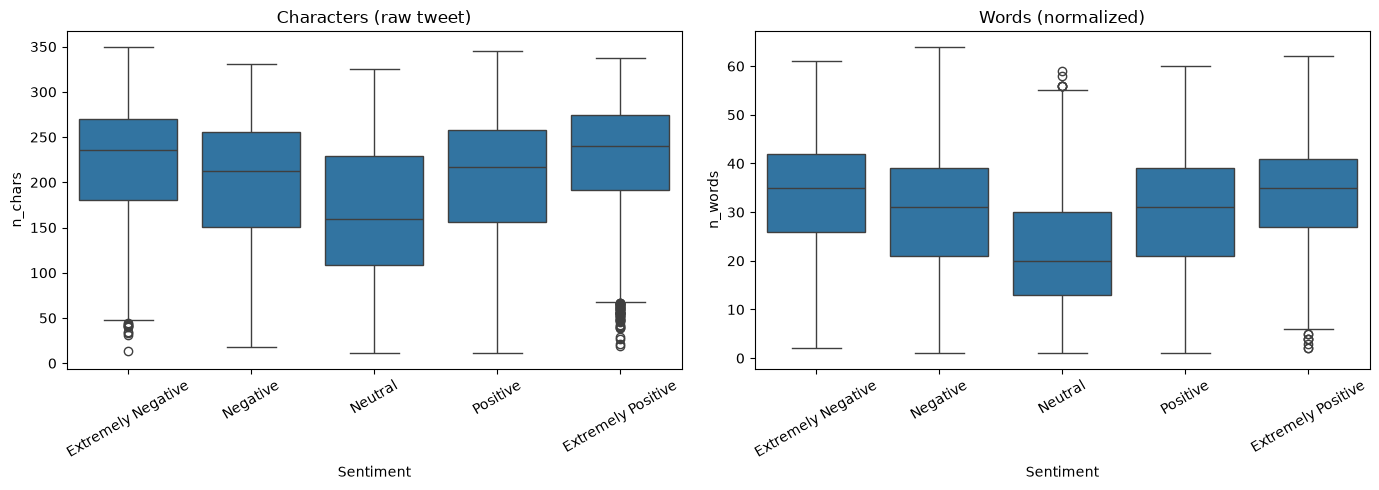

In [ ]:
sentiment_order = ["Extremely Negative", "Negative", "Neutral", "Positive", "Extremely Positive"]
train_df["n_chars"] = train_df["OriginalTweet"].str.len()
train_df["n_words"] = train_df["text_norm"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=train_df, x="Sentiment", y="n_chars", order=sentiment_order, ax=axes[0])
sns.boxplot(data=train_df, x="Sentiment", y="n_words", order=sentiment_order, ax=axes[1])
axes[0].set_title("Characters (raw tweet)")
axes[1].set_title("Words (normalized)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### How common each twitter token is
URLs are far more common in Neutral (60% vs 39–48%), consistent with news-style link tweets. Removing URLs would throw that signal away, so they will be replaced them with a `URL` token. The dedup normalizer still removes them, because there the goal is matching, not prediction. Mentions, hashtags and line breaks are roughly constant across classes; they are cleaning issues, not signal. HTML entities (5–10% of tweets) need unescaping.

In [ ]:

patterns = {
    "url": r"https?://\S+",
    "mention": r"@\w+",
    "hashtag": r"#\w+",
    "html_entity": r"&\w+;",
    "line_break": r"[\r\n]",
}
flags = pd.DataFrame({
    name: train_df["OriginalTweet"].str.contains(p, regex=True)
    for name, p in patterns.items()
})
(flags.groupby(train_df["Sentiment"]).mean().loc[sentiment_order] * 100).round(1)

,url,mention,hashtag,html_entity,line_break
Sentiment,,,,,
Extremely Negative,39.2,22.1,55.7,8.6,30.6
Negative,45.9,24.1,56.6,6.7,29.9
Neutral,60.1,21.9,61.9,4.6,31.8
Positive,48.1,24.4,57.4,7.6,31.7
Extremely Positive,45.3,25.8,56.8,10.1,32.4


In [32]:
#Most frequent words by class
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-z]{3,}\b")
X = cv.fit_transform(train_df["text_norm"])
vocab = cv.get_feature_names_out()

for label in sentiment_order:
    mask = (train_df["Sentiment"] == label).to_numpy()
    counts = np.asarray(X[mask].sum(axis=0)).ravel()
    top = vocab[counts.argsort()[::-1][:15]]
    print(f"{label:>18}: {', '.join(top)}")

Extremely Negative: coronavirus, covid, food, prices, people, panic, supermarket, crisis, buying, store, grocery, consumer, oil, just, stop
          Negative: coronavirus, covid, prices, food, supermarket, store, people, grocery, consumer, demand, panic, pandemic, shopping, online, oil
           Neutral: coronavirus, covid, supermarket, store, prices, grocery, consumer, shopping, online, food, people, pandemic, toiletpaper, new, just
          Positive: coronavirus, covid, store, prices, supermarket, grocery, food, people, consumer, shopping, online, like, pandemic, sanitizer, hand
Extremely Positive: coronavirus, covid, store, supermarket, grocery, food, help, hand, prices, sanitizer, people, like, consumer, workers, online
